In [81]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import pandas as pd
import pystormtracker as pst
from pathlib import Path
import cartopy.crs as ccrs

import sys
import os

module_dir = (Path.cwd() / ".."/".." / "algorithms"/ "track_style_alg").resolve()
sys.path.insert(0,str(module_dir))
import validation as val
import processing as pro
import helpers
from configs import *

import importlib
importlib.reload(val)  # pick up edits in validation.py without restarting the kernel
importlib.reload(pro)  # pick up edits in processing.py without restarting the kernel



<module 'processing' from '/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/algorithms/track_style_alg/processing.py'>

In [82]:
TIME_RANGE = ('1998-12-01 00:00:00', '1999-02-28 18:00:00')  # time range for the validation tracks
#Load the tracks from the trackjson file
tracks = pst.load_tracks('/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/trackjson/19981999_DJF_vo_lmin_6.trackjson')
tracks.metadata.processing

(ProcessingStep(operation='spectral_filter', enabled=True, parameters=mappingproxy({'method': 'sht', 'lmin': 6, 'lmax': 42, 'spectral_taper': 0.1})),)

In [83]:
tracks = pst.load_tracks('/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/trackjson/19981999_DJF_vo_lmin_6.trackjson')
tracks.metadata.processing

(ProcessingStep(operation='spectral_filter', enabled=True, parameters=mappingproxy({'method': 'sht', 'lmin': 6, 'lmax': 42, 'spectral_taper': 0.1})),)

In [84]:
df = helpers.tracks_to_points(tracks)

In [85]:
df = val.clip_to_domain(df, DOMAIN, TIME_RANGE)
len(df['track_id'].unique())

519

In [86]:
tracks = val.dataframe_to_tracks(df, variable = 'vo', scale=1)  # already in s^-1

In [87]:
tracks, summary, points = pro.postprocess_tracks(tracks, **POSTPROCESS_CONFIG)
report = pro.filter_report(summary)
report

raw tracks: 519, kept: 124


,removed_by_this_criterion,removed_only_by_this_criterion
rsplice,388,225
region,170,5
edge,80,0
peak,0,0
time,0,0


/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


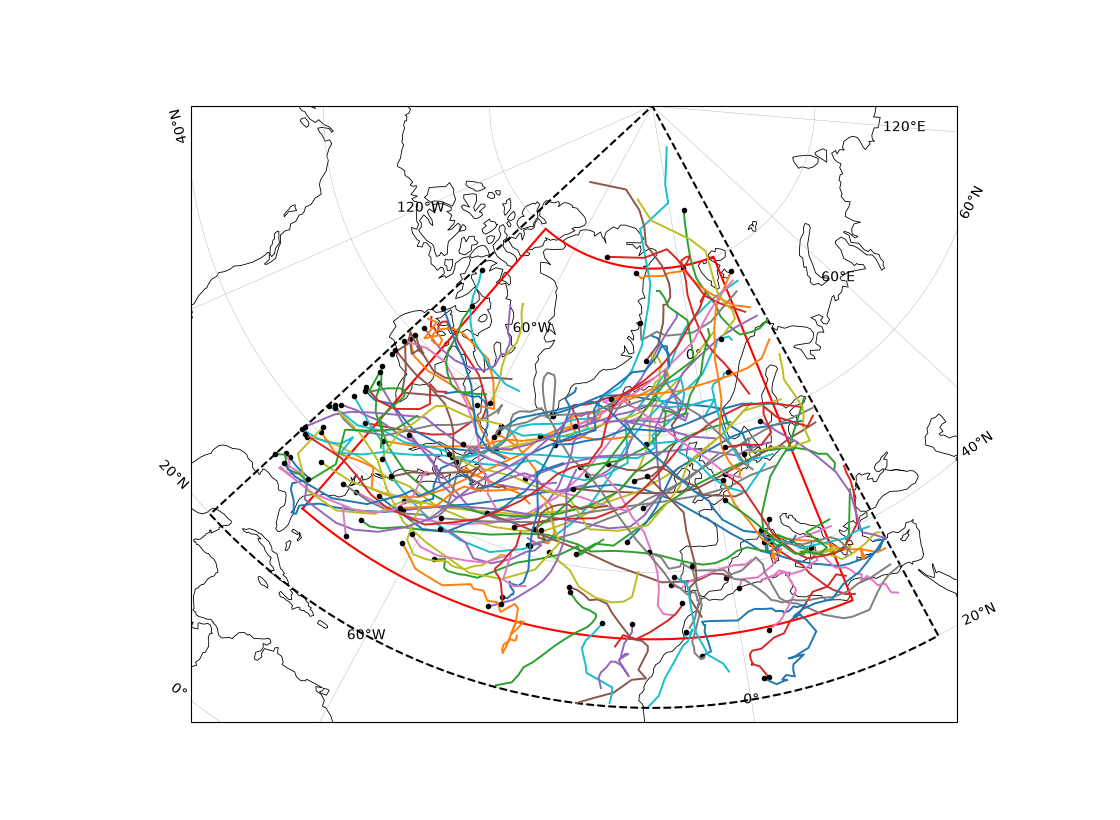

In [88]:
ax= val.plot_regional_tracks(tracks, region=REGION, domain=DOMAIN)

In [89]:
tracks_coarse = pst.load_tracks('/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/trackjson/19981999_DJF_vo_lmin_6_coarse.trackjson')
tracks_coarse.metadata.processing

(ProcessingStep(operation='spectral_filter', enabled=True, parameters=mappingproxy({'method': 'sht', 'lmin': 6, 'lmax': 42, 'spectral_taper': 0.1})),)

In [90]:
df_coarse = helpers.tracks_to_points(tracks_coarse)

In [91]:
df_coarse = val.clip_to_domain(df_coarse, DOMAIN, TIME_RANGE)
len(df_coarse['track_id'].unique())


522

In [92]:
tracks_coarse = val.dataframe_to_tracks(df_coarse, variable = 'vo', scale=1)  # already in s^-1

In [93]:
tracks_coarse, summary_coarse, points_coarse = pro.postprocess_tracks(tracks_coarse, **POSTPROCESS_CONFIG)

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


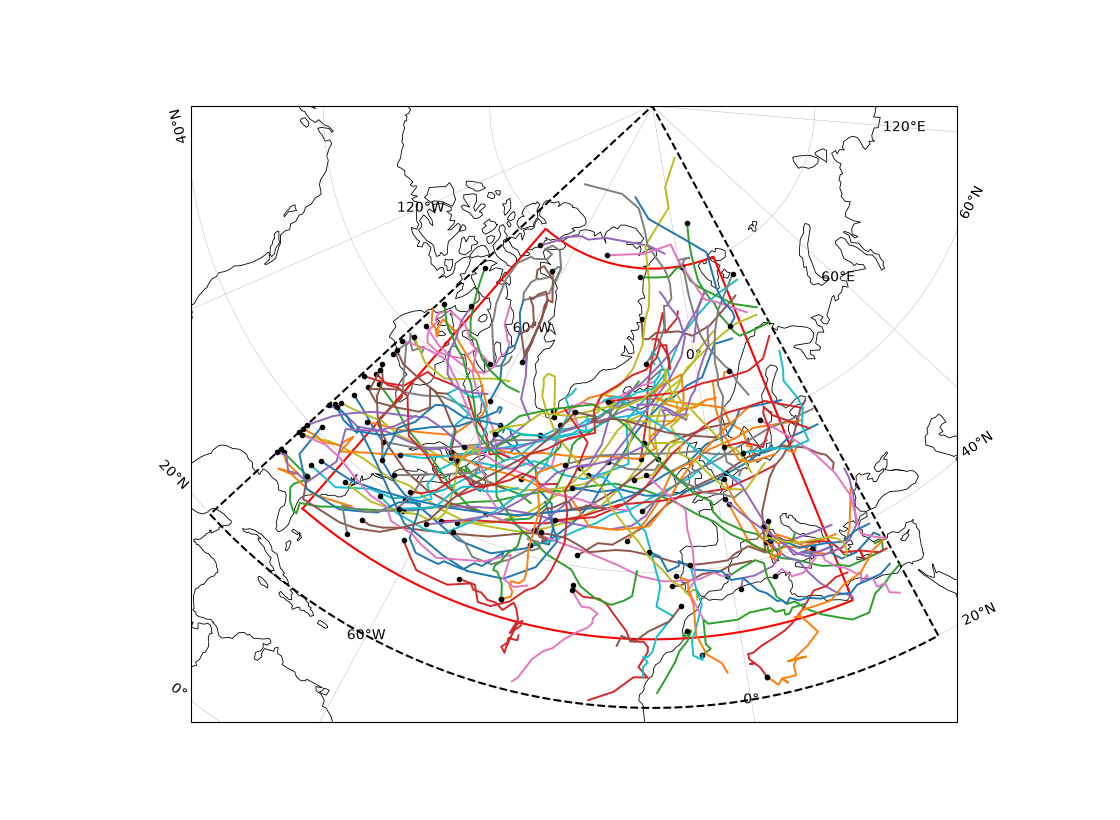

In [94]:
ax= val.plot_regional_tracks(tracks_coarse, region=REGION, domain=DOMAIN)

In [95]:
report = pro.filter_report(summary_coarse)

raw tracks: 522, kept: 126


In [96]:
comparison, matches_df = val.compare_to_validation(tracks, tracks_coarse, matching="global_assignment",
                                               max_mean_separation_deg=2.0, min_overlap_fraction=0.6,
                                               variable="vo")

In [97]:
# result table 
results_df = pd.Series({
    "Hits": comparison.tp,
    "Miss": comparison.fn,
    "Extra": comparison.fp,
    "F1": comparison.f1, #
    "Precision": comparison.precision,
    "Recall": comparison.recall,
})
results_df

Hits         115.000000
Miss           9.000000
Extra         11.000000
F1             0.920000
Precision      0.912698
Recall         0.927419
dtype: float64

Number of verified tracks: 115
Number of extra tracks: 11
Number of verified validation tracks: 115
Number of missed tracks: 9
22.875
22.75


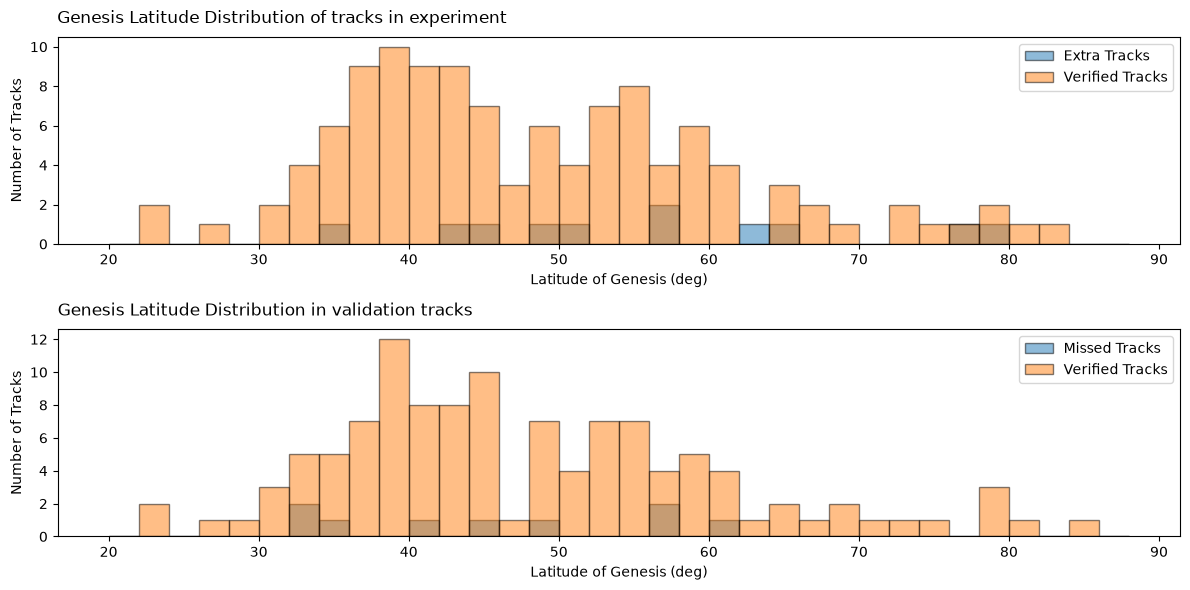

In [98]:
#creating list for verified
#creating list for verified
verified_tracks = matches_df['candidate_id']
verified_val = matches_df['reference_id']

#remember to filter the summary dataframes to only include the tracks that were kept
summary_val_filtered = summary[summary['keep'] == True]
summary_filtered = summary_coarse[summary_coarse['keep'] == True]


kept_tracks = summary_filtered[summary_filtered['track_id'].isin(verified_tracks)]
extra_tracks = summary_filtered[~summary_filtered['track_id'].isin(verified_tracks)]

kept_val_tracks = summary_val_filtered[summary_val_filtered['track_id'].isin(verified_val)]
missed_tracks = summary_val_filtered[~summary_val_filtered['track_id'].isin(verified_val)]






print(f"Number of verified tracks: {len(kept_tracks)}")
print(f"Number of extra tracks: {len(extra_tracks)}")
print(f"Number of verified validation tracks: {len(kept_val_tracks)}")
print(f"Number of missed tracks: {len(missed_tracks)}")

print(np.min(kept_tracks["lat_genesis"].values))
print(np.min(kept_val_tracks["lat_genesis"].values))

genesis_ver = kept_tracks["lat_genesis"].values
genesis_missed = missed_tracks["lat_genesis"].values
genesis_ex = extra_tracks["lat_genesis"].values
genesis_val = kept_val_tracks["lat_genesis"].values

counts, edges = np.histogram(genesis_ver, bins=np.arange(20, 90, 2), density=False)
counts_missed, edges_missed = np.histogram(genesis_missed, bins=np.arange(20, 90, 2), density=False)
counts_dis, edges_dis = np.histogram(genesis_ex, bins=np.arange(20, 90, 2), density=False)
counts_val, edges_val = np.histogram(genesis_val, bins=np.arange(20, 90, 2), density=False)

fig, ax = plt.subplots(2,1,figsize=(12, 6), sharex=False)
ax[0].bar(edges_dis[:-1], counts_dis, width=2, align="edge", edgecolor="black", label="Extra Tracks", alpha=0.5)
ax[0].bar(edges[:-1], counts, width=2, align="edge", edgecolor="black", label="Verified Tracks", alpha=0.5)

ax[1].bar(edges_missed[:-1], counts_missed, width=2, align="edge", edgecolor="black", label="Missed Tracks", alpha=0.5)
ax[1].bar(edges_val[:-1], counts_val, width=2, align="edge", edgecolor="black", label="Verified Tracks", alpha=0.5)


ax[0].set_xlabel("Latitude of Genesis (deg)")
ax[0].set_ylabel("Number of Tracks")
ax[0].set_title("Genesis Latitude Distribution of tracks in experiment", fontsize=12, pad=10, x=0.2)
ax[0].legend()

ax[1].set_xlabel("Latitude of Genesis (deg)")
ax[1].set_ylabel("Number of Tracks")
ax[1].set_title("Genesis Latitude Distribution in validation tracks", fontsize=12, pad=10, x=0.185)
ax[1].legend()

plt.tight_layout()

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


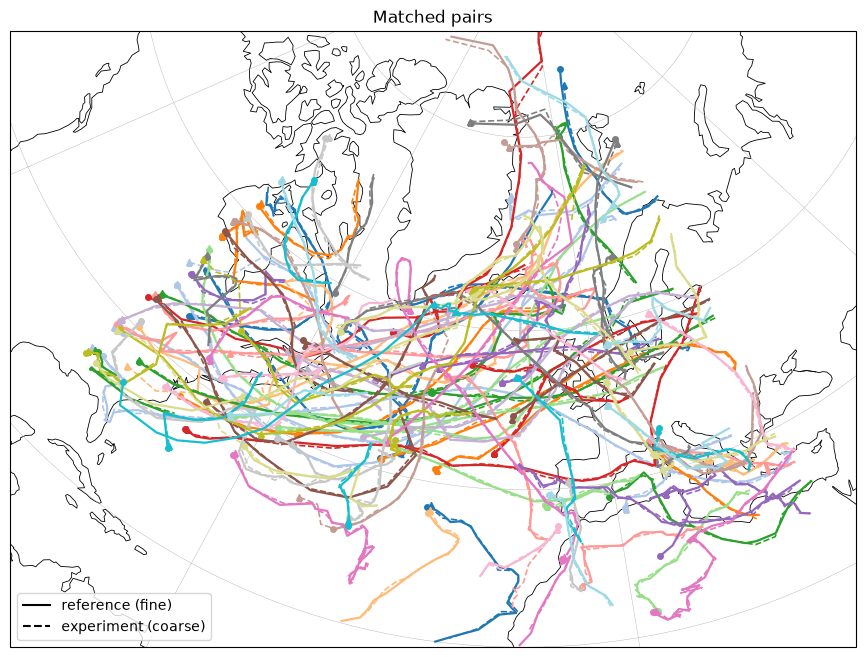

In [99]:
pc = ccrs.PlateCarree()
proj = ccrs.LambertConformal(central_longitude=-15, central_latitude=55)

# look up tracks by id
ref_by_id = {tr.track_id: tr for tr in tracks}
cand_by_id = {tr.track_id: tr for tr in tracks_coarse}

fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={"projection": proj})
ax.coastlines(linewidth=0.6)
ax.gridlines(linewidth=0.3)
ax.set_extent([DOMAIN[0], DOMAIN[1], DOMAIN[2], 85], crs=pc)

colors = plt.cm.tab20(np.linspace(0, 1, len(matches_df)))
for row, c in zip(matches_df.itertuples(), colors):
    ref = ref_by_id[int(row.reference_id)]
    cand = cand_by_id[int(row.candidate_id)]
    ax.plot(ref.lons, ref.lats, "-", color=c, lw=1.6, transform=pc)
    ax.plot(cand.lons, cand.lats, "--", color=c, lw=1.2, transform=pc)
    ax.plot(ref.lons[0], ref.lats[0], "o", color=c, ms=4, transform=pc)    # reference start
    ax.plot(cand.lons[0], cand.lats[0], "^", color=c, ms=4, transform=pc)  # experiment start

ax.plot([], [], "k-", label="reference (fine)")
ax.plot([], [], "k--", label="experiment (coarse)")
ax.legend(loc="lower left")
ax.set_title(f"Matched pairs")
plt.show()

Text(0.5, 1.0, 'Matched pairs')

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


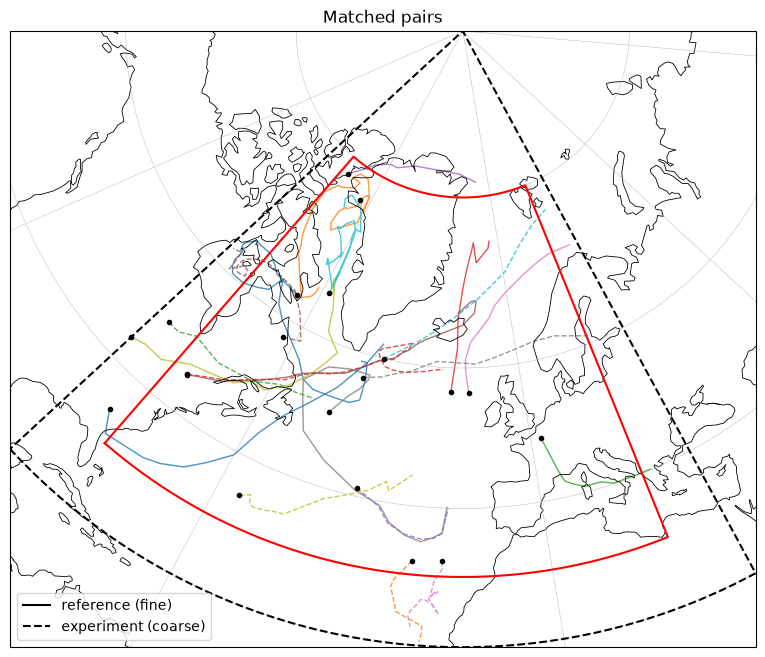

In [100]:
pc = ccrs.PlateCarree()
proj = ccrs.LambertConformal(central_longitude=-15, central_latitude=55)

fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={"projection": proj})
ax.coastlines(linewidth=0.6)
ax.gridlines(linewidth=0.3)
ax.set_extent([DOMAIN[0], DOMAIN[1], DOMAIN[2], 90], crs=pc)


for tr in tracks_coarse:
    if tr.track_id in extra_tracks['track_id'].values:
        ax.plot(tr.lons, tr.lats, "-", alpha=0.8, lw=1, transform=pc, zorder=0)
        ax.plot(tr.lons[0], tr.lats[0], "k.", ms=6, transform=pc)

for tr in tracks:
    if tr.track_id in missed_tracks['track_id'].values:
        ax.plot(tr.lons, tr.lats, "--", alpha=0.8, lw=1, transform=pc, zorder=0)
        ax.plot(tr.lons[0], tr.lats[0], "k.", ms=6, transform=pc)
for box, style in ((DOMAIN, dict(color="k", linestyle="--")), (REGION, dict(color="red"))):
        # densify the edges so they follow parallels/meridians in the projection
        lo = np.linspace(box[0], box[1], 100)
        la = np.linspace(box[2], box[3], 100)
        xs = np.concatenate([lo, np.full(100, box[1]), lo[::-1], np.full(100, box[0])])
        ys = np.concatenate([np.full(100, box[2]), la, np.full(100, box[3]), la[::-1]])
        ax.plot(xs, ys, lw=1.5, transform=pc, **style)  

ax.plot([], [], "k-", label="reference (fine)")
ax.plot([], [], "k--", label="experiment (coarse)")
ax.legend(loc="lower left")
ax.set_title(f"Matched pairs")